# Retail Demand Forecasting — EDA

Explore historical sales, stores, promotions, transactions, holidays and oil prices.

Run cells from top to bottom. The notebook saves key charts and a merged dataset for later modelling.

## 1. Imports and paths

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

cwd = Path.cwd()
PROJECT = cwd.parent if cwd.name == "notebooks" else cwd
DATA = PROJECT / "data"
OUT = PROJECT / "outputs"
OUT.mkdir(exist_ok=True)

required = ["train.csv", "stores.csv", "holidays_events.csv", "transactions.csv", "oil.csv"]
missing = [f for f in required if not (DATA / f).exists()]
if missing:
    raise FileNotFoundError(f"Missing files in {DATA}: {missing}")

## 2. Load data

In [2]:
sales = pd.read_csv(DATA / "train.csv", parse_dates=["date"])
stores = pd.read_csv(DATA / "stores.csv")
holidays = pd.read_csv(DATA / "holidays_events.csv", parse_dates=["date"])
transactions = pd.read_csv(DATA / "transactions.csv", parse_dates=["date"])
oil = pd.read_csv(DATA / "oil.csv", parse_dates=["date"])

for name, df in {
    "Sales": sales, "Stores": stores, "Holidays": holidays,
    "Transactions": transactions, "Oil": oil
}.items():
    print(f"{name}: {df.shape}")

display(sales.head())

Sales: (3000888, 6)
Stores: (54, 5)
Holidays: (350, 6)
Transactions: (83488, 3)
Oil: (1218, 2)


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


## 3. Data quality and summary

In [3]:
quality = pd.DataFrame({
    "missing": sales.isna().sum(),
    "missing_%": (sales.isna().mean() * 100).round(2)
})
display(quality)
print("Exact duplicate rows:", sales.duplicated().sum())
print("Duplicate date-store-family keys:",
      sales.duplicated(["date", "store_nbr", "family"]).sum())
display(sales[["sales", "onpromotion"]].describe().round(2))
print("Date range:", sales.date.min().date(), "to", sales.date.max().date())
print("Stores:", sales.store_nbr.nunique(), "| Product families:", sales.family.nunique())

,missing,missing_%
id,0,0.0
date,0,0.0
store_nbr,0,0.0
family,0,0.0
sales,0,0.0
onpromotion,0,0.0


Exact duplicate rows: 0
Duplicate date-store-family keys: 0


,sales,onpromotion
count,3000888.00,3000888.00
mean,357.78,2.60
std,1102.00,12.22
min,0.00,0.00
25%,0.00,0.00
50%,11.00,0.00
75%,195.85,0.00
max,124717.00,741.00


Date range: 2013-01-01 to 2017-08-15
Stores: 54 | Product families: 33


## 4. Daily sales trend

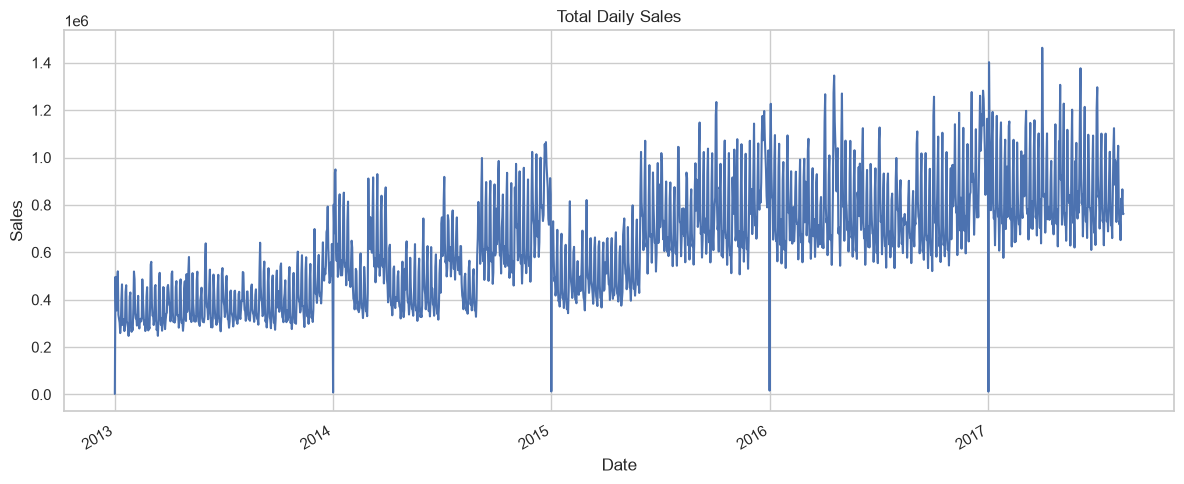

In [4]:
daily_sales = sales.groupby("date")["sales"].sum()
daily_sales.plot()
plt.title("Total Daily Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.tight_layout()
plt.savefig(OUT / "daily_sales.png", dpi=140)
plt.show()

## 5. Sales by product family

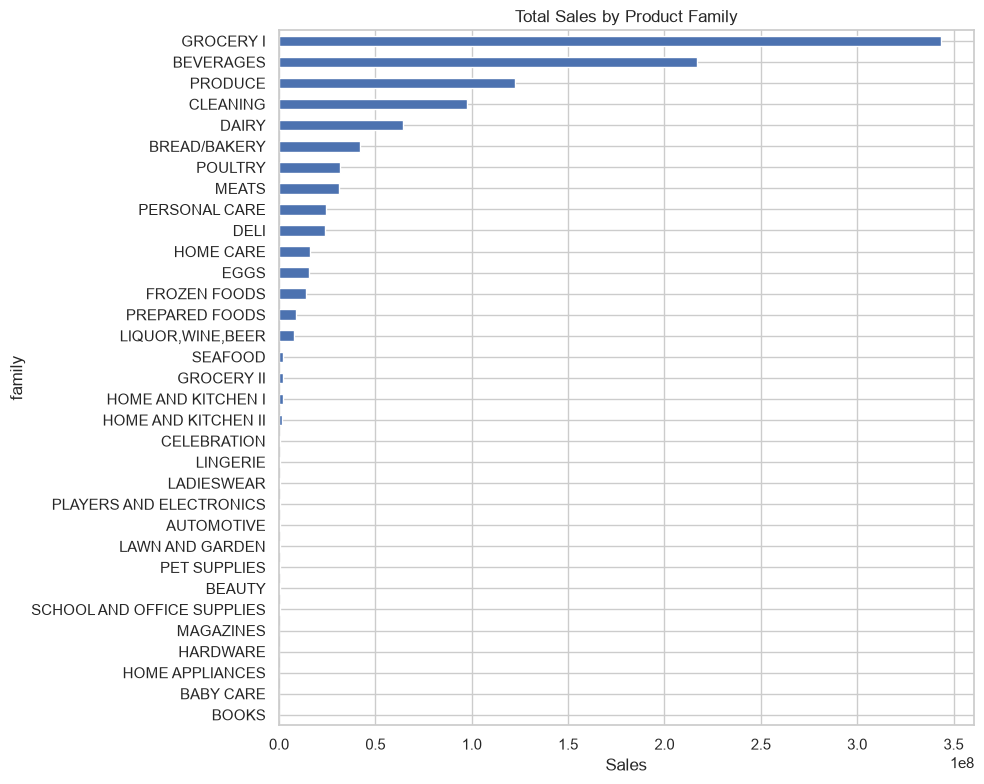

In [5]:
family_sales = sales.groupby("family")["sales"].sum().sort_values()
family_sales.plot(kind="barh", figsize=(10, 8))
plt.title("Total Sales by Product Family")
plt.xlabel("Sales")
plt.tight_layout()
plt.savefig(OUT / "category_sales.png", dpi=140)
plt.show()

## 6. Sales by store

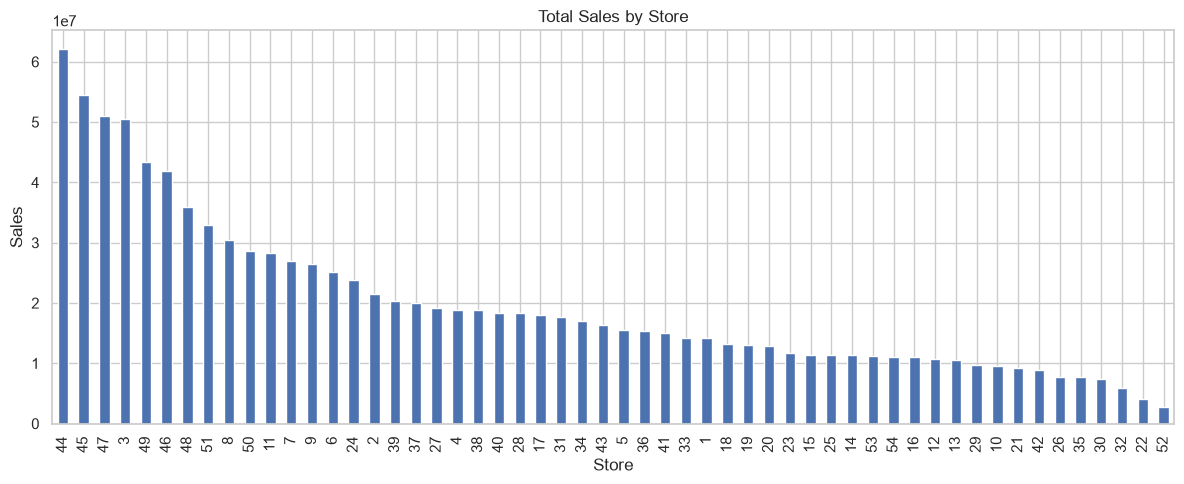

,total_sales
store_nbr,
44,6.208755e+07
45,5.449801e+07
47,5.094831e+07
3,5.048191e+07
49,4.342010e+07
46,4.189606e+07
48,3.593313e+07
51,3.291149e+07
8,3.049429e+07


In [6]:
store_sales = sales.groupby("store_nbr")["sales"].sum().sort_values(ascending=False)
store_sales.plot(kind="bar", figsize=(12, 5))
plt.title("Total Sales by Store")
plt.xlabel("Store")
plt.ylabel("Sales")
plt.tight_layout()
plt.savefig(OUT / "store_sales.png", dpi=140)
plt.show()
display(store_sales.head(10).to_frame("total_sales"))

## 7. Promotion analysis

,count,mean,median
promotion,,,
No promotion,2389559,158.246681,3.0
Promotion,611329,1137.693730,373.0


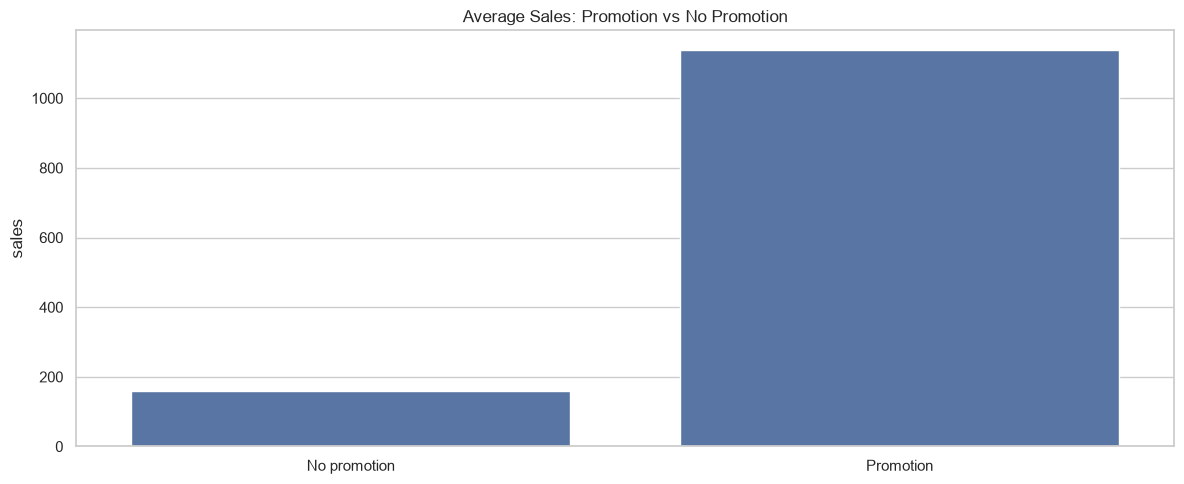

In [7]:
sales["promotion"] = sales["onpromotion"].gt(0).map(
    {True: "Promotion", False: "No promotion"}
)
display(sales.groupby("promotion")["sales"].agg(["count", "mean", "median"]))
sns.barplot(data=sales, x="promotion", y="sales", estimator="mean", errorbar=None)
plt.title("Average Sales: Promotion vs No Promotion")
plt.xlabel("")
plt.tight_layout()
plt.savefig(OUT / "promotion_impact.png", dpi=140)
plt.show()

## 8. Weekly and monthly patterns

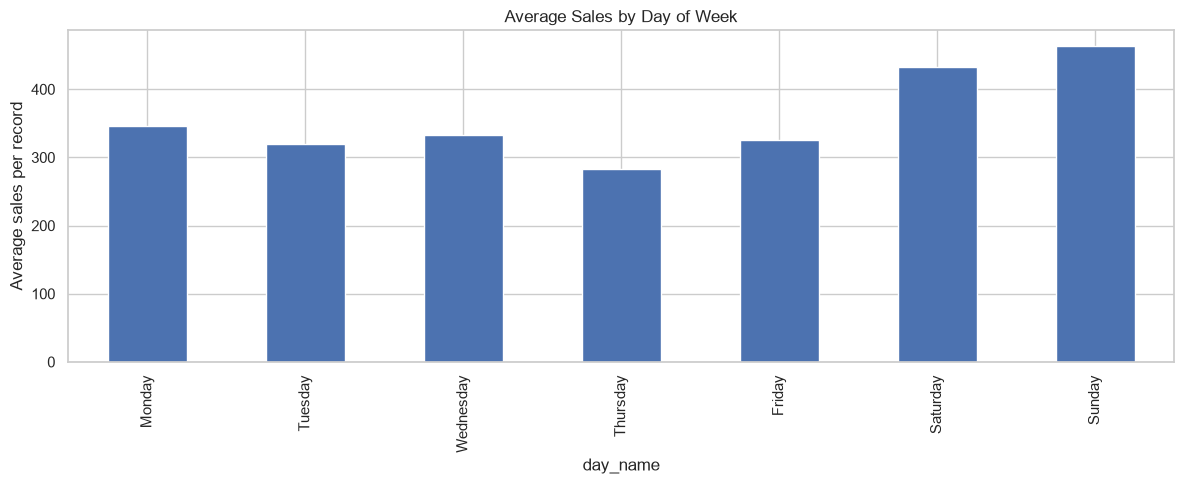

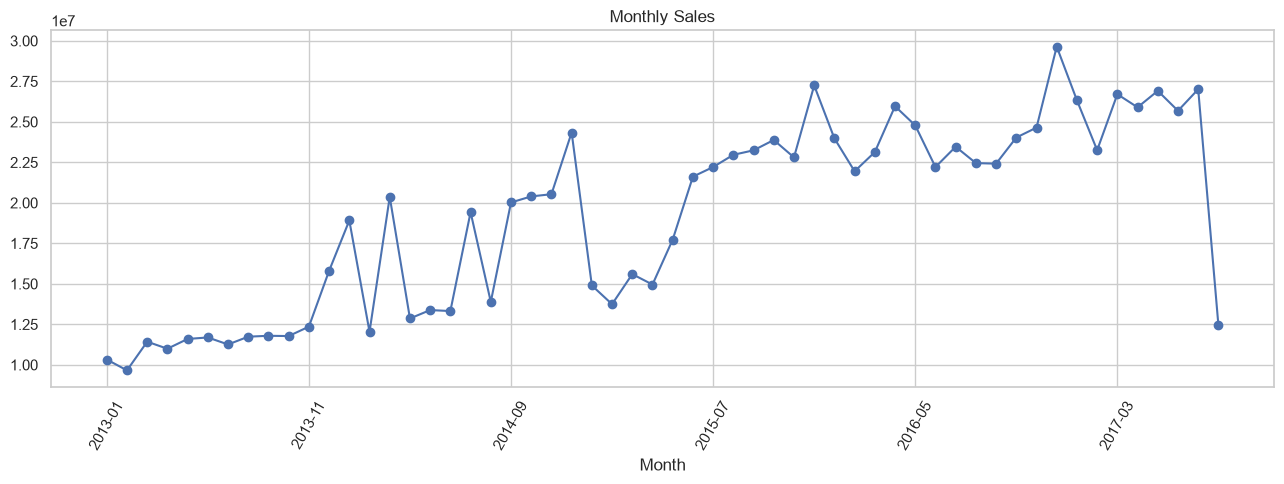

In [8]:
sales["day_name"] = sales.date.dt.day_name()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday = sales.groupby("day_name")["sales"].mean().reindex(order)
weekday.plot(kind="bar")
plt.title("Average Sales by Day of Week")
plt.ylabel("Average sales per record")
plt.tight_layout()
plt.savefig(OUT / "weekday_sales.png", dpi=140)
plt.show()

monthly = sales.groupby(sales.date.dt.to_period("M"))["sales"].sum()
monthly.index = monthly.index.astype(str)
monthly.plot(marker="o", figsize=(13, 5))
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.xticks(rotation=60)
plt.tight_layout()
plt.savefig(OUT / "monthly_sales.png", dpi=140)
plt.show()

## 9. Transactions, holidays and oil

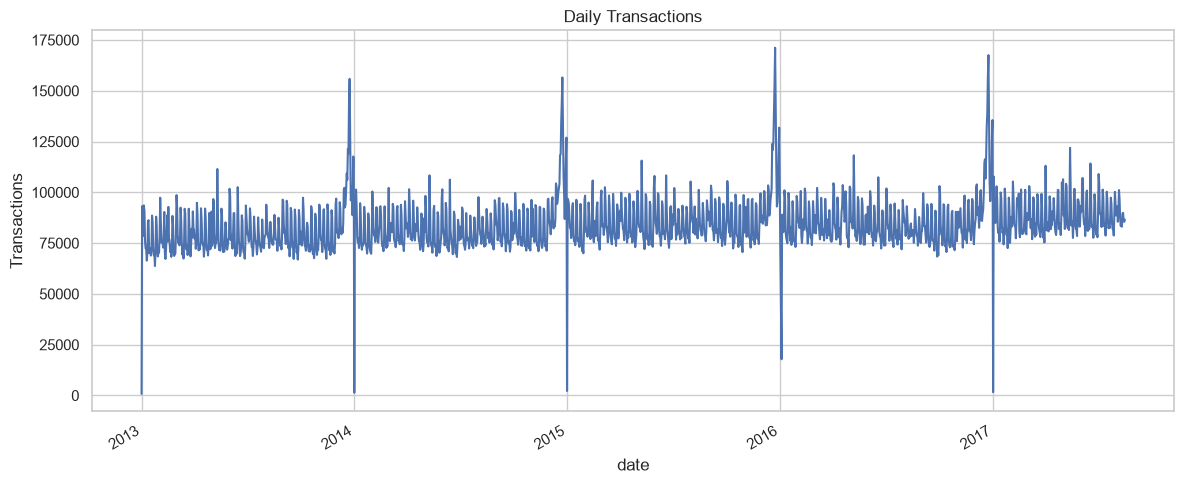

,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False


,count
type,
Holiday,221
Event,56
Additional,51
Transfer,12
Bridge,5
Work Day,5


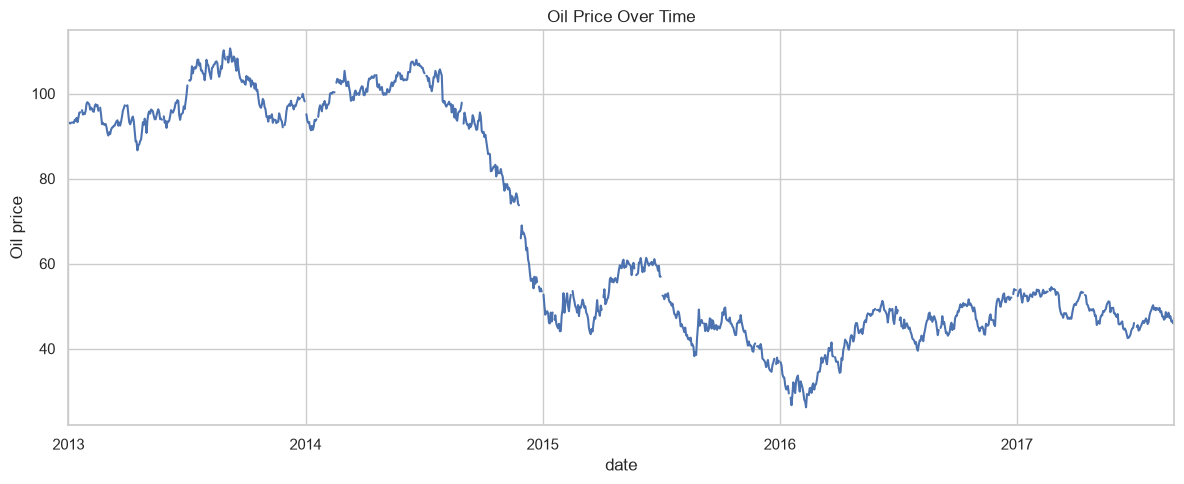

In [9]:
transactions.groupby("date")["transactions"].sum().plot()
plt.title("Daily Transactions")
plt.ylabel("Transactions")
plt.tight_layout()
plt.savefig(OUT / "transactions.png", dpi=140)
plt.show()

display(holidays.head())
display(holidays["type"].value_counts().to_frame("count"))

oil.plot(x="date", y="dcoilwtico", legend=False)
plt.title("Oil Price Over Time")
plt.ylabel("Oil price")
plt.tight_layout()
plt.savefig(OUT / "oil_prices.png", dpi=140)
plt.show()

## 10. Merge datasets

In [10]:
retail = sales.merge(stores, on="store_nbr", how="left")
retail = retail.merge(transactions, on=["date", "store_nbr"], how="left")
retail = retail.merge(oil, on="date", how="left")

# Use unique holiday dates so sales rows are not duplicated.
holiday_dates = holidays[["date"]].drop_duplicates().assign(is_holiday=1)
retail = retail.merge(holiday_dates, on="date", how="left")
retail["is_holiday"] = retail["is_holiday"].fillna(0).astype(int)

print("Merged dataset:", retail.shape)
display(retail.head())
retail.to_csv(DATA / "retail_merged.csv", index=False)
print("Saved:", DATA / "retail_merged.csv")

Merged dataset: (3000888, 15)


,id,date,store_nbr,family,sales,onpromotion,promotion,day_name,city,state,type,cluster,transactions,dcoilwtico,is_holiday
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,No promotion,Tuesday,Quito,Pichincha,D,13,NaN,NaN,1
1,1,2013-01-01,1,BABY CARE,0.0,0,No promotion,Tuesday,Quito,Pichincha,D,13,NaN,NaN,1
2,2,2013-01-01,1,BEAUTY,0.0,0,No promotion,Tuesday,Quito,Pichincha,D,13,NaN,NaN,1
3,3,2013-01-01,1,BEVERAGES,0.0,0,No promotion,Tuesday,Quito,Pichincha,D,13,NaN,NaN,1
4,4,2013-01-01,1,BOOKS,0.0,0,No promotion,Tuesday,Quito,Pichincha,D,13,NaN,NaN,1


Saved: c:\Users\darks\Desktop\proj1\retail\data\retail_merged.csv


## 11. Initial findings

Fill these in after reviewing the charts:

- Highest-selling product families:
- Highest-performing stores:
- Weekly/monthly sales patterns:
- Promotion pattern:
- Data quality issues:
- Potential forecasting features:

**Next:** feature engineering, weather and social-trend integration, then time-based model validation.